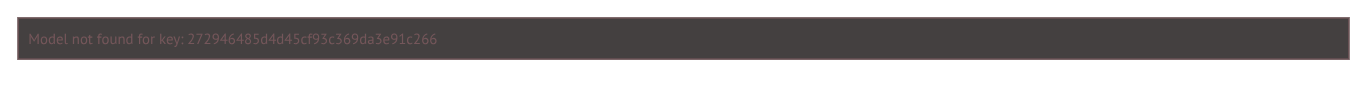

In [ ]:
import marimo as mo

# 03 · EDA: iWildCam data + where our models lose Macro-F1

| | |
|---|---|
| **Experiment(s)** | A1 (EDA for the leaderboard push): data, long tail, camera locations, sequences, day/night, image sizes; error analysis of the team's models; post-hoc what-ifs |
| **Paper / report** | The EDA report page (built from the findings bundle below) and its figures |
| **Env** | Notebook kernel only (numpy, pandas, matplotlib, pillow, huggingface_hub, wandb). No GPU needed |
| **Inputs** | iWildCam v2.0 at `DATA_ROOT` (reuses `~/absgd-iwildcam/data`, else fetched from HF `emmilly/iwildcam-wilds-v2`). Predictions: HF `emmilly/sclr-iwildcam-outputs` `runs/dfn-vith14-ft-lr1e-05-s0/{best.json, metrics.csv, epochs/epochNN.npz, epochs/zeroshot.npz}`; HF `emmilly/absgd-iwildcam-outputs` `runs/resnet50-absgd-lam1.1-s0/{metrics.csv, logits/fixednorm__epochNN.npz}`; optional teammates' predictions `eda/external/<model>__<split>.csv` (see below) |
| **Outputs** | HF `emmilly/sclr-iwildcam-outputs`: `eda/image_stats.csv.gz`, `eda/findings.json` (every table + the gallery lists: the report is built from it), `eda/classes.csv`, `eda/locations_test.csv`, `eda/fig_*.png`, `eda/thumbs/<idx>.jpg` + `eda/thumbs_manifest.json`; markers `runs/iwildcam-eda/_done/`. W&B run `iwildcam-eda` (figures + headline numbers) |
| **Keys** | KEYS cell below, or `HF_TOKEN` / `WANDB_API_KEY` environment variables. Put the placeholders back before exporting |
| **How to run** | Run all, on the Marimo box (the images are there). With a terminal: `nohup python 03_eda_iwildcam.py > ~/sclr-iwildcam/logs/03_eda_iwildcam.log 2>&1 &` |
| **Teammates' models** | Upload a CSV per split to `eda/external/<model>__<split>.csv` (model name without `__`; split in `val`, `test`, `id_test`) with columns `filename` (as in WILDS `metadata.csv`) and `y_pred` (WILDS class index), optionally `conf`. They are picked up on the next run (the fingerprint changes) |
| **Memory / batch notes** | ~1.5 GB RAM (three models' logits). Image statistics read all 203k images at 1/8 scale with `IMAGE_WORKERS` processes |
| **Resume after a crash** | Re-run. Image statistics are done once (marker); the analysis and thumbnails are recomputed only when their inputs changed (fingerprints), otherwise read back from HF |
| **Runtime** | First run ~10-15 min (image statistics ~5-10 min, analysis ~2 min, thumbnails ~1 min); later runs ~2 min |
| **Forked from** | — (first version; structure of `02_results_dfn_vith14.py`) |

**What-ifs** are post-hoc changes to saved outputs (no training): logit adjustment for the class prior, a fine-tuned + zero-shot
logit ensemble (a cheap output-space stand-in for WiSE-FT), and averaging over camera sequences. Each knob is chosen on **OOD val** and
then reported once on OOD test. Sequence averaging uses metadata at test time: check the WILDS rules before relying on it.

In [ ]:
# ══════════════ KEYS: paste yours between the quotes (only if not already set as environment variables) ══════════════
HF_TOKEN = "#"          # ← HF token of account emmilly, WRITE access (huggingface.co/settings/tokens)
WANDB_API_KEY = "#"    # ← W&B API key (wandb.ai/authorize), member of team-support-vectors-idlf26
# ════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
# Exported .ipynb files keep whatever is pasted above: put the placeholders back before sharing a file.
if "YOUR_TOKEN" in HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")
if "YOUR_KEY" in WANDB_API_KEY:
    WANDB_API_KEY = os.environ.get("WANDB_API_KEY", "")
os.environ["HF_TOKEN"] = HF_TOKEN
if WANDB_API_KEY:
    os.environ["WANDB_API_KEY"] = WANDB_API_KEY
print(f"HF_TOKEN set: {bool(HF_TOKEN)} | WANDB_API_KEY set: {bool(WANDB_API_KEY)}")

HF_TOKEN set: True | WANDB_API_KEY set: True


In [ ]:
import io
import json
import os
import sys
import time
from pathlib import Path

In [ ]:
NOTEBOOK = "03"
EXP_ID = "A1"
WORK_ROOT = Path(os.environ.get("SCLR_WORK_ROOT", str(Path.home() / "sclr-iwildcam"))).expanduser()
os.environ["SCLR_WORK_ROOT"] = str(WORK_ROOT)
_absgd_data = Path.home() / "absgd-iwildcam" / "data"
DATA_ROOT = (Path(os.environ["SCLR_DATA_ROOT"]) if os.environ.get("SCLR_DATA_ROOT") else
             _absgd_data if (_absgd_data / "iwildcam_v2.0" / ".verified.json").exists() else WORK_ROOT / "data")
DFN_RUN = "dfn-vith14-ft-lr1e-05-s0"
# Models to analyse. kind "sclr": runs of 01_train_dfn_vith14 (epoch "best" = best.json, -1 = zero-shot);
# kind "absgd": runs of the ResNet-50 replication (epoch "best" = best OOD val Macro-F1 of that variant).
MODELS = [
    {"name": "dfn-ft", "label": "DFN ViT-H/14 fine-tuned", "kind": "sclr", "run": DFN_RUN, "epoch": "best"},
    {"name": "dfn-zs", "label": "DFN ViT-H/14 zero-shot", "kind": "sclr", "run": DFN_RUN, "epoch": -1},
    {"name": "resnet50", "label": "ResNet-50 ABSGD (seed 0)", "kind": "absgd", "run": "resnet50-absgd-lam1.1-s0",
     "variant": "fixednorm", "epoch": "best"},
]
PRIMARY = "dfn-ft"            # the model whose errors the galleries show
ZEROSHOT = "dfn-zs"           # its zero-shot counterpart (ensemble what-if, "fine-tuning broke it" gallery)
SPLITS_EDA = ["val", "test", "id_test"]   # val = OOD val (tuning), test = OOD test (reported), id_test = ID comparison
IMAGE_WORKERS = 16
THUMB_WIDTH = 320
LA_TAUS = [round(0.1 * _i, 2) for _i in range(21)]       # logit adjustment: logits - tau * log(train prior)
ENS_ALPHAS = [round(0.05 * _i, 2) for _i in range(21)]   # logits = (1 - a) * finetuned + a * zeroshot
SEQ_BETAS = [round(0.1 * _i, 1) for _i in range(11)]     # p = (1 - b) * p + b * mean of p over the sequence
GALLERY = {"overview_train": 12, "overview_test": 6, "rare_classes": 16, "background_classes": 5, "night_errors": 8,
           "night_right": 4, "confusion_pairs": 8, "ft_broke": 10, "empty_each": 6, "confident_errors": 10}
ALLOW_MISSING_IMAGES = os.environ.get("SCLR_EDA_ALLOW_MISSING") == "1"   # local tests on a fake dataset only
ANALYSIS_VERSION = 2          # bump after editing the analysis cell: it is part of the fingerprint, so old findings are redone
STAGES = {"image_stats": True, "analysis": True, "thumbs": True}
FORCE = set()                 # e.g. {"analysis"} recomputes even if nothing changed

[wc] sclr_common 1.1.0 (embedded 1.1.0) at /home/marimo/sclr-iwildcam/common
[hub] HF account: emmilly


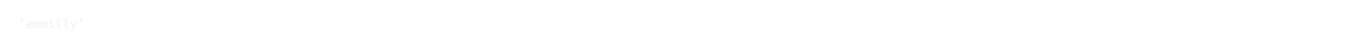

In [ ]:
import base64 as _b64
import hashlib as _hl
import importlib as _il
import importlib.util as _ilu
import subprocess as _sp
from pathlib import Path as _P

# >>> EMBEDDED sclr_common (written by tools/make_standalone.py; do not edit) >>>
_MODULE_VERSION = "1.1.0"
_MODULE_MD5 = "7e38768c07eb5dd9bea0be087db7b749"
_MODULE_B64 = (
    "..."
)
# <<< EMBEDDED sclr_common <<<
for _pkg in ("numpy", "pandas", "huggingface_hub", "wandb"):
    if _ilu.find_spec(_pkg) is None:
        print(f"[wc] installing {_pkg} into the notebook kernel")
        _sp.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=True)
_src = _b64.b64decode(_MODULE_B64)
assert _hl.md5(_src).hexdigest() == _MODULE_MD5, "embedded shared module is corrupt"
_dir = _P(WORK_ROOT) / "common"
_dir.mkdir(parents=True, exist_ok=True)
(_dir / "sclr_common.py").write_bytes(_src)
if str(_dir) not in sys.path:
    sys.path.insert(0, str(_dir))
wc = _il.reload(sys.modules["sclr_common"]) if "sclr_common" in sys.modules else _il.import_module("sclr_common")
print(f"[wc] sclr_common {wc.VERSION} (embedded {_MODULE_VERSION}) at {_dir}")
wc.Hub(HF_TOKEN).check_account()

In [ ]:
import importlib.util as _ilu2
import subprocess as _sp2
for _mod, _pkg in (("matplotlib", "matplotlib"), ("PIL", "pillow")):
    if _ilu2.find_spec(_mod) is None:
        print(f"[libs] installing {_pkg} into the notebook kernel")
        _sp2.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=True)
import numpy as np
import pandas as pd

In [ ]:
hub = wc.Hub(HF_TOKEN)
CACHE = WORK_ROOT / "hub_copy"
stages = wc.Stages(hub, wc.EDA_RUN, STAGES, FORCE, CACHE)
RES_CSV = CACHE / wc.resources_path(wc.EDA_RUN)
wb_run, log_fn = wc.wandb_init(
    wc.EDA_RUN, "analysis", [f"exp:{EXP_ID}", f"nb:{NOTEBOOK}", "arch:dfn-vith14", "user:emmilly"],
    {"exp_id": EXP_ID, "notebook": NOTEBOOK, "models": MODELS, "primary": PRIMARY, "zeroshot": ZEROSHOT,
     "la_taus": LA_TAUS, "ens_alphas": ENS_ALPHAS, "seq_betas": SEQ_BETAS, "gallery": GALLERY,
     "module_version": wc.VERSION, "git_commit": "unknown",
     "packages": wc.package_versions(("numpy", "pandas", "huggingface_hub", "wandb", "matplotlib", "pillow"))})

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: enamugan (team-me-and-me) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run iwildcam-eda
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /marimo/wandb/run-20261103_165826-iwildcam-eda
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run iwildcam-eda
wandb: ⭐️ View project at https://wandb.ai/team-support-vectors-idlf26/iwilds
wandb: 🚀 View run at https://wandb.ai/team-support-vectors-idlf26/iwilds/runs/iwildcam-eda


In [ ]:
# iWildCam metadata (species, camera location, sequence, time) for all 203k images
DATA_DIR = DATA_ROOT / wc.DATA_VERSION
if not (DATA_DIR / ".verified.json").exists():
    with mo.status.spinner(title="iWildCam is not on this machine: fetching it from the HF mirror (12 GB, ~10-20 min)"):
        wc.ensure_iwildcam(WORK_ROOT, data_root=DATA_ROOT)
meta, CLASS_NAMES = wc.load_metadata(DATA_DIR)
N_CLASSES = len(CLASS_NAMES)
EMPTY_Y = 0 if CLASS_NAMES[0].strip().lower() == "empty" else None
TRAIN_COUNTS = np.bincount(meta.loc[meta["split"] == "train", "y"], minlength=N_CLASSES)
print(f"[data] {DATA_DIR} | {len(meta):,} images | {N_CLASSES} classes (class 0 = {CLASS_NAMES[0]!r}) | "
      f"split sizes {meta['split'].value_counts().to_dict()}")

[data] free disk at /home/marimo/sclr-iwildcam/data: 9223372037 GB (need ~30 GB)
[data] fetching the verified archive from HF emmilly/iwildcam-wilds-v2 (12.0 GB)
[data] archive OK (11.96 GB, sha256 05c872f46eee4431...); extracting
[data] verification: OK | {'data_dir': '/home/marimo/sclr-iwildcam/data/iwildcam_v2.0', 'split_sizes': {'train': 129809, 'test': 42791, 'val': 14961, 'id_test': 8154, 'id_val': 7314}, 'n_classes': 182, 'metadata_md5': 'ab4905ee40ac45ab66ddb176d473a4b4', 'n_files_missing': 0, 'n_decode_checked': 1000, 'n_decode_failed': 0, 'problems': []}
[data] /home/marimo/sclr-iwildcam/data/iwildcam_v2.0 | 203,029 images | 100000 classes (class 0 = 'empty') | split sizes {'train': 129809, 'test': 42791, 'val': 14961, 'id_test': 8154, 'id_val': 7314}


[image_stats] readable 203,029/203,029 | infrared (grayscale) 47.9% of readable | most common sizes {(597, 448): 86836, (796, 448): 72095, (560, 448): 43977}



Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            


  ...py/eda/image_stats.csv.gz:  17%|█▋        |  524kB / 3.05MB            


  ...py/eda/image_stats.csv.gz:  17%|█▋        |  524kB / 3.05MB            
Processing Files (0 / 1)      :  17%|█▋        |  524kB / 3.05MB,   ???B/s  

New Data Upload               :  17%|█▋        |  524kB / 3.05MB,   ???B/s  


  ...py/eda/image_stats.csv.gz:  86%|████████▌ | 2.62MB / 3.05MB            
Processing Files (0 / 1)      :  86%|████████▌ | 2.62MB / 3.05MB,   ???B/s  

New Data Upload               :  86%|████████▌ | 2.62MB / 3.05MB,   ???B/s  


  ...py/eda/image_stats.csv.gz: 100%|██████████| 3.05MB / 3.05MB            
Processing Files (1 / 1)      : 100%|██████████| 3.05MB / 3.05MB,   ???B/s  

New Data Upload               : 100%|██████████| 3.05MB / 3.05MB,   ???B/s  


  ...py/eda/image_stats.csv.gz: 100%|██████████| 3.05MB / 3.05MB     

[resources] image_stats: ok | wall 0.01 h | peak GPU 0.0 GB | peak RAM 5.25 GB | NVIDIA RTX PRO 6000 Blackwell Server Edition
RESOURCES {"stage": "image_stats", "start": "2026-11-03 17:08:03", "host": "e1e0120e-48c9-47c3-a20f-020d7b39b503-vd6xp", "gpu_name": "NVIDIA RTX PRO 6000 Blackwell Server Edition", "n_images": 203029, "status": "ok", "wall_time_h": 0.0052, "gpu_hours": 0.0052, "peak_gpu_mem_gb": 0.0, "peak_ram_gb": 5.25}
[iwildcam-eda] stage image_stats: marked done


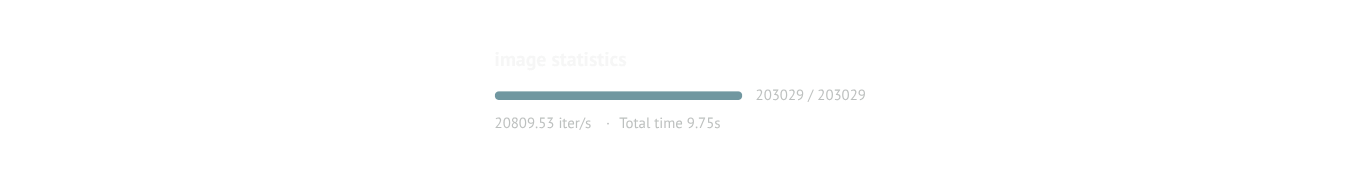

In [ ]:
# Stage image_stats: size, brightness, colourfulness and an infrared (grayscale) flag for every image
_path = wc.eda_path("image_stats", "csv.gz")
if stages.should_run("image_stats"):
    with wc.track_resources("image_stats", log_fn=log_fn, csv_path=RES_CSV, n_images=len(meta)):
        _paths = [DATA_DIR / "train" / _f for _f in meta["filename"]]
        _prog = lambda _it, _n: mo.status.progress_bar(_it, total=_n, title="image statistics", show_eta=True, show_rate=True)  # noqa: E731
        img = wc.image_stats(_paths, IMAGE_WORKERS, progress=_prog)
        img.insert(0, "idx", meta["idx"].to_numpy())
        _bad = int((~img["readable"]).sum())
        _sizes = img[img["readable"]].groupby(["width", "height"]).size().nlargest(3).to_dict()
        print(f"[image_stats] readable {len(img) - _bad:,}/{len(img):,} | infrared (grayscale) {100 * img['ir'].mean():.1f}% of readable | "
              f"most common sizes {_sizes}")
        if _bad > (len(img) if ALLOW_MISSING_IMAGES else 0.001 * len(img)):
            raise RuntimeError(f"{_bad} images could not be read: check {DATA_DIR / 'train'}")
        _local = CACHE / _path
        _local.parent.mkdir(parents=True, exist_ok=True)
        img.to_csv(_local, index=False)
        hub.put({_path: _local}, "A1: image statistics")
    stages.mark_done("image_stats", {"n": len(img), "unreadable": _bad, "md5": wc.md5_file(_local)})
else:
    _p = hub.download(_path, CACHE)
    img = pd.read_csv(_p) if _p else pd.DataFrame()
    print(f"[image_stats] read back: {len(img):,} rows" if len(img) else "[image_stats] none (stage off and nothing on HF)")
if len(img):
    meta_img = meta.merge(img[["idx", "width", "height", "brightness", "chroma", "ir"]], on="idx", how="left")
    meta_img["ir"] = meta_img["ir"].astype(float)
else:
    meta_img = meta.assign(width=np.nan, height=np.nan, brightness=np.nan, chroma=np.nan, ir=np.nan)
IMG_MD5 = (stages.done_info("image_stats") or {}).get("md5")

[preds] dfn-ft: epoch 7 | val F1 50.29 | test F1 45.75 | id_test F1 59.74
[preds] dfn-zs: epoch -1 | val F1 20.21 | test F1 17.43 | id_test F1 16.93
[preds] resnet50: epoch 15 | val F1 39.01 | test F1 34.35 | id_test F1 47.03


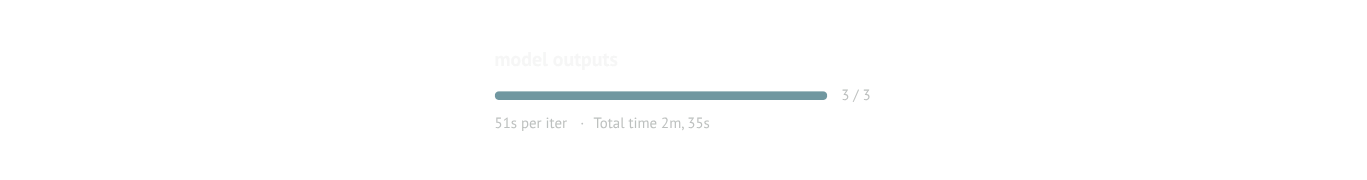

In [ ]:
# Per-image predictions of every model on val / test / id_test, aligned with the metadata rows
by_split = {_s: meta_img[meta_img["split"] == _s].sort_values("pos").reset_index(drop=True) for _s in wc.SPLITS}
Y = {_s: by_split[_s]["y"].to_numpy() for _s in wc.SPLITS}
preds, model_info = {}, []

def _from_logits(_lg):
    _p = wc.softmax_np(_lg)
    return {"pred": _p.argmax(1), "conf": _p.max(1), "logits": _lg}

for _m in mo.status.progress_bar(MODELS, title="model outputs", show_eta=True, show_rate=True):
    if _m["kind"] == "sclr":
        _epoch = int(hub.get_json(f"{wc.run_dir(_m['run'])}/best.json")["epoch"]) if _m["epoch"] == "best" else int(_m["epoch"])
        _repo, _path = wc.OUTPUTS_REPO, wc.epoch_outputs_path(_m["run"], _epoch)
        _z = np.load(hub.download(_path, CACHE, repo=_repo))
        _lg = {_s: _z[f"{_s}_logits"].astype(np.float32) for _s in SPLITS_EDA}
        _lab = {_s: _z[f"{_s}_labels"] for _s in SPLITS_EDA}
    elif _m["kind"] == "absgd":
        _repo = wc.ABSGD_OUTPUTS_REPO
        _mt = pd.read_csv(hub.download(wc.metrics_path(_m["run"]), CACHE, repo=_repo))
        _w = _mt[_mt["variant"] == _m["variant"]].pivot_table(index="epoch", columns="split", values="f1_macro")
        _epoch = int(_w["val"].idxmax()) if _m["epoch"] == "best" else int(_m["epoch"])
        _path = wc.val_preds_path(_m["run"], _epoch, _m["variant"])
        _z = np.load(hub.download(_path, CACHE, repo=_repo))
        _lg, _lab = {_s: _z[_s].astype(np.float32) for _s in SPLITS_EDA}, None
    else:
        raise ValueError(f"unknown model kind {_m['kind']!r}")
    for _s in SPLITS_EDA:
        if len(_lg[_s]) != len(Y[_s]) or (_lab is not None and not np.array_equal(_lab[_s], Y[_s])):
            raise RuntimeError(f"{_m['name']} {_s}: saved outputs do not line up with metadata.csv (rows {len(_lg[_s])} vs {len(Y[_s])})")
    preds[_m["name"]] = {_s: _from_logits(_lg[_s]) for _s in SPLITS_EDA}
    model_info.append({**_m, "epoch": _epoch, "repo": _repo, "path": _path, "source": "logits"})
    print(f"[preds] {_m['name']}: epoch {_epoch} | " + " | ".join(
        f"{_s} F1 {100 * wc.f1_of(Y[_s], preds[_m['name']][_s]['pred']):.2f}" for _s in SPLITS_EDA))

# Teammates' predictions (CSV: filename, y_pred[, conf]); missing images count as wrong
_ext = [_p for _p in hub.list("eda/external/") if _p.endswith(".csv")]
for _name in sorted({_p.split("/")[-1].rsplit("__", 1)[0] for _p in _ext}):
    _by = {}
    for _s in SPLITS_EDA:
        _p = hub.download(wc.eda_external_path(_name, _s), CACHE) if wc.eda_external_path(_name, _s) in _ext else None
        if _p is None:
            continue
        _df = pd.read_csv(_p)
        _pos = pd.Series(by_split[_s].index.to_numpy(), index=by_split[_s]["filename"].to_numpy())
        _df = _df[_df["filename"].isin(_pos.index)]
        _pred = np.full(len(Y[_s]), N_CLASSES, dtype=np.int64)   # N_CLASSES = "no prediction" (never correct)
        _pred[_pos[_df["filename"]].to_numpy()] = _df["y_pred"].astype(int).to_numpy()
        _conf = np.full(len(Y[_s]), np.nan, dtype=np.float32)
        if "conf" in _df:
            _conf[_pos[_df["filename"]].to_numpy()] = _df["conf"].astype(float).to_numpy()
        _by[_s] = {"pred": _pred, "conf": _conf, "logits": None, "coverage": float(len(_df) / len(Y[_s]))}
        model_info.append({"name": _name, "label": _name, "kind": "external", "split": _s, "path": wc.eda_external_path(_name, _s),
                           "md5": wc.md5_file(_p), "coverage": _by[_s]["coverage"], "source": "csv"})
    if _by:
        preds[_name] = _by
        print(f"[preds] external {_name}: " + " | ".join(f"{_s} F1 {100 * wc.f1_of(Y[_s], _v['pred']):.2f} "
                                                          f"(coverage {100 * _v['coverage']:.0f}%)" for _s, _v in _by.items()))

In [ ]:
# Stage analysis: every table of the report + the gallery lists, in one findings.json
fingerprint = wc.md5_json({"analysis_version": ANALYSIS_VERSION, "models": model_info, "image_stats": IMG_MD5, "module": wc.VERSION, "primary": PRIMARY,
                           "zeroshot": ZEROSHOT, "grids": [LA_TAUS, ENS_ALPHAS, SEQ_BETAS], "gallery": GALLERY,
                           "splits": SPLITS_EDA})
_prev = stages.done_info("analysis") or {}
findings, analysis_recomputed = {}, False
if stages.enabled.get("analysis", True) and (stages.forced("analysis") or _prev.get("fingerprint") != fingerprint):
    with wc.track_resources("analysis", log_fn=log_fn, csv_path=RES_CSV):
        F = {"meta": {"created": time.strftime("%Y-%m-%d %H:%M"), "module_version": wc.VERSION, "fingerprint": fingerprint,
                      "models": model_info, "primary": PRIMARY, "zeroshot": ZEROSHOT, "data_dir": str(DATA_DIR),
                      "class_names": list(CLASS_NAMES), "empty_y": EMPTY_Y,
                      "analysis_version": ANALYSIS_VERSION}}
        _label = {_m["name"]: _m.get("label", _m["name"]) for _m in model_info}
        _has_ir = by_split["test"]["ir"].notna().any()
        _name = np.asarray(list(CLASS_NAMES) + ["(no prediction)"], dtype=object)

        # ── splits, locations, sequences ──
        _rows = []
        for _s in wc.SPLITS:
            _d = by_split[_s]
            _seq = _d.groupby("sequence")
            _rows.append({"split": _s, "images": len(_d), "locations": int(_d["location"].nunique()),
                          "sequences": int(_d["sequence"].nunique()), "classes": int(_d["y"].nunique()),
                          "empty_share": float((_d["y"] == EMPTY_Y).mean()) if EMPTY_Y is not None else None,
                          "ir_share": float(_d["ir"].mean()) if _has_ir else None,
                          "imgs_per_seq_mean": float(_seq.size().mean()), "imgs_per_seq_median": float(_seq.size().median()),
                          "imgs_per_seq_max": int(_seq.size().max()), "seq_single_label_share": float((_seq["y"].nunique() == 1).mean()),
                          "date_min": _d["datetime"].min(), "date_max": _d["datetime"].max()})
        F["splits"] = _rows
        _locs = {_s: set(by_split[_s]["location"]) for _s in wc.SPLITS}
        F["location_overlap"] = {f"{_a}&{_b}": len(_locs[_a] & _locs[_b]) for _a in wc.SPLITS for _b in wc.SPLITS if _a < _b}
        _tl = by_split["train"]["location"].value_counts().to_numpy()
        F["train_location_sizes"] = {"sorted_counts": [int(_c) for _c in _tl],
                                     "top10pct_share": float(_tl[:max(len(_tl) // 10, 1)].sum() / _tl.sum()),
                                     "n_locations": int(len(_tl))}

        # ── classes: counts, locations, per-model F1 ──
        _cls = pd.DataFrame({"y": np.arange(N_CLASSES), "species": list(CLASS_NAMES)})
        for _s in wc.SPLITS:
            _cls[f"n_{_s}"] = np.bincount(Y[_s], minlength=N_CLASSES)
        for _s in ("train", "test"):
            _cls[f"{_s}_locations"] = by_split[_s].groupby("y")["location"].nunique().reindex(range(N_CLASSES), fill_value=0).to_numpy()
        _cls["train_bin"] = wc.train_bin(_cls["n_train"])
        _cls["loc_bin"] = wc.location_bin(_cls["train_locations"])
        if _has_ir:
            _cls["train_ir_share"] = by_split["train"].groupby("y")["ir"].mean().reindex(range(N_CLASSES)).to_numpy()
            _cls["test_ir_share"] = by_split["test"].groupby("y")["ir"].mean().reindex(range(N_CLASSES)).to_numpy()
        _pc = {}
        for _mn, _ps in preds.items():
            for _s, _v in _ps.items():
                _t = wc.per_class_table(Y[_s], _v["pred"], N_CLASSES)
                _pc[(_mn, _s)] = _t
                _cls[f"f1_{_mn}_{_s}"] = np.where(_t["scored"], _t["f1"], np.nan)
                if _mn == PRIMARY and _s == "test":
                    _cls["precision_test"], _cls["recall_test"], _cls["n_pred_test"] = _t["precision"], _t["recall"], _t["n_pred"]
        F["classes"] = wc.records(_cls)
        _scored = _cls[_cls["n_test"] > 0]
        F["long_tail"] = {"classes_total": N_CLASSES, "classes_with_train": int((_cls["n_train"] > 0).sum()),
                          "scored_test_classes": int(len(_scored)),
                          "scored_lt10_train": int((_scored["n_train"] < 10).sum()),
                          "scored_zero_train": int((_scored["n_train"] == 0).sum()),
                          "scored_le2_train_locations": int((_scored["train_locations"] <= 2).sum()),
                          "val_classes": int((_cls["n_val"] > 0).sum()),
                          "val_and_test_classes": int(((_cls["n_val"] > 0) & (_cls["n_test"] > 0)).sum()),
                          "test_only_classes": int(((_cls["n_val"] == 0) & (_cls["n_test"] > 0)).sum()),
                          "train_sorted_counts": [int(_c) for _c in np.sort(TRAIN_COUNTS)[::-1]]}

        # ── model summary + Macro-F1 budget ──
        _ms, _bud, _locb = [], [], []
        for _mn, _ps in preds.items():
            for _s, _v in _ps.items():
                _ms.append({"model": _mn, "label": _label.get(_mn, _mn), "split": _s,
                            **{_k: 100 * _x for _k, _x in wc.score_predictions(Y[_s], _v["pred"]).items()},
                            "coverage": _v.get("coverage", 1.0)})
            if "test" in _ps:
                _b = wc.f1_budget(_pc[(_mn, "test")], TRAIN_COUNTS)
                _bud += wc.records(_b.assign(model=_mn))
                _sc = _cls[_cls["n_test"] > 0]
                _g = _sc.groupby("loc_bin")[f"f1_{_mn}_test"].agg(["size", "mean"]).rename(columns={"size": "n_classes", "mean": "mean_f1"})
                _g = _g.reindex([_x for _x in wc.EDA_LOC_LABELS if _x in _g.index])
                _g["points_lost"] = 100 * (_sc.groupby("loc_bin")[f"f1_{_mn}_test"].apply(lambda _f: float((1 - _f).sum()))) / len(_sc)
                _locb += wc.records(_g.reset_index().assign(model=_mn))
        F["models_summary"], F["f1_budget"], F["f1_by_train_locations"] = wc.records(pd.DataFrame(_ms)), _bud, _locb

        # ── ID vs OOD per class (primary) ──
        if "id_test" in preds[PRIMARY]:
            _both = _cls[(_cls["n_id_test"] > 0) & (_cls["n_test"] > 0)]
            _id, _ood = _both[f"f1_{PRIMARY}_id_test"], _both[f"f1_{PRIMARY}_test"]
            F["shift_categories"] = {"robust (ID>=0.5, OOD>=0.5)": int(((_id >= 0.5) & (_ood >= 0.5)).sum()),
                                     "breaks under shift (ID>=0.5, OOD<0.5)": int(((_id >= 0.5) & (_ood < 0.5)).sum()),
                                     "hard everywhere (ID<0.5, OOD<0.5)": int(((_id < 0.5) & (_ood < 0.5)).sum()),
                                     "better OOD (ID<0.5, OOD>=0.5)": int(((_id < 0.5) & (_ood >= 0.5)).sum()),
                                     "n_classes": int(len(_both))}

        # ── confusions, empty errors, confidence (primary, OOD test) ──
        _yt, _pt = Y["test"], preds[PRIMARY]["test"]["pred"]
        _conf = wc.top_confusions(_yt, _pt, 40)
        _conf["species"], _conf["pred_species"] = _name[_conf["y"].to_numpy()], _name[_conf["pred"].to_numpy()]
        _conf["same_genus"] = [str(_a).split(" ")[0] == str(_b).split(" ")[0] for _a, _b in zip(_conf["species"], _conf["pred_species"])]
        F["confusions"] = wc.records(_conf)
        _err = _yt != _pt
        F["errors"] = {"n_test": int(len(_yt)), "n_errors": int(_err.sum())}
        if EMPTY_Y is not None:
            _animal = _yt != EMPTY_Y
            F["errors"].update({"false_empty": int((_animal & (_pt == EMPTY_Y)).sum()), "animal_images": int(_animal.sum()),
                                "false_animal": int((~_animal & (_pt != EMPTY_Y)).sum()), "empty_images": int((~_animal).sum()),
                                "errors_involving_empty": int((_err & ((_pt == EMPTY_Y) | (_yt == EMPTY_Y))).sum())})
        _cf = preds[PRIMARY]["test"]["conf"]
        _bins = np.linspace(0, 1, 11)
        _bi = np.clip(np.digitize(_cf, _bins) - 1, 0, 9)
        F["calibration"] = [{"conf_lo": float(_bins[_i]), "n": int((_bi == _i).sum()),
                             "acc": float((~_err[_bi == _i]).mean()) if (_bi == _i).any() else None,
                             "mean_conf": float(_cf[_bi == _i].mean()) if (_bi == _i).any() else None} for _i in range(10)]
        F["errors"]["confident_errors_ge_0.9"] = int((_err & (_cf >= 0.9)).sum())

        # ── model agreement ──
        F["agreement"] = {}
        for _other in [_m for _m in preds if _m != PRIMARY and "test" in preds[_m]]:
            _a = wc.agreement(_yt, _pt, preds[_other]["test"]["pred"])
            F["agreement"][_other] = _a
        if ZEROSHOT in preds:
            _zs = preds[ZEROSHOT]["test"]["pred"]
            _broke = (_zs == _yt) & (_pt != _yt)
            _bc = pd.Series(_yt[_broke]).value_counts()
            F["ft_broke_classes"] = [{"y": int(_k), "species": _name[_k], "n": int(_v), "n_test": int((_yt == _k).sum())}
                                     for _k, _v in _bc.head(20).items()]
            _better = _cls[(_cls["n_test"] > 0) & (_cls[f"f1_{ZEROSHOT}_test"] > _cls[f"f1_{PRIMARY}_test"])]
            F["zs_beats_ft_classes"] = wc.records(_better[["y", "species", "n_train", "n_test", f"f1_{ZEROSHOT}_test", f"f1_{PRIMARY}_test"]]
                                                  .sort_values(f"f1_{ZEROSHOT}_test", ascending=False))

        # ── camera locations (OOD test, primary) ──
        _t = by_split["test"].assign(pred=_pt, correct=~_err)
        _lt = _t.groupby("location").agg(n=("y", "size"), acc=("correct", "mean"), n_species=("y", "nunique"),
                                         ir_share=("ir", "mean"), errors=("correct", lambda _c: int((~_c).sum())))
        _lt["top_species"] = _t.groupby("location")["species"].agg(lambda _x: _x.value_counts().index[0])
        _lt["macro_f1"] = _t.groupby("location").apply(lambda _g: wc.f1_of(_g["y"].to_numpy(), _g["pred"].to_numpy()))
        _lt = _lt.sort_values("errors", ascending=False).reset_index()
        F["locations_test"] = wc.records(_lt)
        _ce = np.cumsum(_lt["errors"].to_numpy()) / max(_lt["errors"].sum(), 1)
        F["error_concentration"] = {"n_locations": int(len(_lt)), "top5_share": float(_ce[min(4, len(_ce) - 1)]),
                                    "top10_share": float(_ce[min(9, len(_ce) - 1)]),
                                    "locations_for_half": int(np.searchsorted(_ce, 0.5) + 1)}

        # ── time of day, infrared, image sizes ──
        F["hours"] = {_s: by_split[_s]["hour"].value_counts(normalize=True).reindex(range(24), fill_value=0).round(4).tolist()
                      for _s in wc.SPLITS}
        if _has_ir:
            _ir, _day = _t["ir"] == 1, _t["ir"] == 0   # unreadable images (NaN) are in neither
            F["ir_test"] = {"ir_share": float(_ir.mean()),
                            "acc_day": float(_t.loc[_day, "correct"].mean()), "acc_ir": float(_t.loc[_ir, "correct"].mean()),
                            "f1_day": 100 * wc.f1_of(_t.loc[_day, "y"].to_numpy(), _t.loc[_day, "pred"].to_numpy()),
                            "f1_ir": 100 * wc.f1_of(_t.loc[_ir, "y"].to_numpy(), _t.loc[_ir, "pred"].to_numpy()),
                            "error_share_ir": float((_ir & ~_t["correct"]).sum() / max((~_t["correct"]).sum(), 1))}
            _all = pd.concat(by_split.values())
            F["image_sizes"] = [{"width": int(_w), "height": int(_h), "n": int(_n)} for (_w, _h), _n in
                                _all.groupby(["width", "height"]).size().nlargest(10).items()]
            F["brightness"] = {_s: np.histogram(by_split[_s]["brightness"].dropna(), bins=26, range=(0, 260))[0].tolist() for _s in wc.SPLITS}

        # ── validation vs test: does OOD val pick the right epoch? ──
        _vt = []
        _dm = pd.read_csv(hub.download(wc.metrics_path(DFN_RUN), CACHE))
        _dw = _dm.pivot_table(index="epoch", columns="split", values="f1_macro").reset_index()
        _vt += wc.records(_dw[_dw["epoch"] >= 0].assign(model="dfn-ft"))
        for _m in model_info:
            if _m.get("kind") == "absgd":
                _am = pd.read_csv(hub.download(wc.metrics_path(_m["run"]), CACHE, repo=wc.ABSGD_OUTPUTS_REPO))
                _aw = _am[_am["variant"] == _m["variant"]].pivot_table(index="epoch", columns="split", values="f1_macro").reset_index()
                _vt += wc.records(_aw.assign(model=_m["name"]))
        _vtd = pd.DataFrame(_vt)
        F["val_vs_test"] = {"epochs": _vt, "spearman": {_k: float(_g["val"].corr(_g["test"], method="spearman"))
                                                        for _k, _g in _vtd.groupby("model")},
                            "test_at_val_pick": {_k: float(_g.loc[_g["val"].idxmax(), "test"]) for _k, _g in _vtd.groupby("model")},
                            "best_test": {_k: float(_g["test"].max()) for _k, _g in _vtd.groupby("model")}}

        # ── what-ifs (post hoc, tuned on OOD val, reported on OOD test) ──
        _lp = np.log((TRAIN_COUNTS + 1.0) / (TRAIN_COUNTS + 1.0).sum()).astype(np.float32)
        _yv = Y["val"]
        _W = {"baseline": {}}
        for _mn in preds:
            if any(preds[_mn].get(_s, {}).get("logits") is None for _s in ("val", "test")):
                continue
            _lv, _lt2 = preds[_mn]["val"]["logits"], preds[_mn]["test"]["logits"]
            _W["baseline"][_mn] = {"val_f1": 100 * wc.f1_of(_yv, _lv.argmax(1)), "test_f1": 100 * wc.f1_of(_yt, _lt2.argmax(1))}
            _la = wc.sweep(LA_TAUS, lambda _g: _lv - _g * _lp, lambda _g: _lt2 - _g * _lp, _yv, _yt, "tau")
            _W.setdefault("logit_adjust", {})[_mn] = {"sweep": wc.records(_la), "chosen": wc.pick_on_val(_la).to_dict()}
        # stacked in logit space: zero-shot ensemble (logit mix, the output-space analogue of WiSE-FT) -> logit adjustment
        # -> sequence averaging of the resulting probabilities. Each knob is chosen on OOD val given the previous ones.
        _cv, _ct = preds[PRIMARY]["val"]["logits"], preds[PRIMARY]["test"]["logits"]
        _sv, _st = by_split["val"]["sequence"].to_numpy(), by_split["test"]["sequence"].to_numpy()
        _steps = [{"step": "fine-tuned (as trained)", "val_f1": _W["baseline"][PRIMARY]["val_f1"], "test_f1": _W["baseline"][PRIMARY]["test_f1"]}]
        if ZEROSHOT in preds and preds[ZEROSHOT]["val"].get("logits") is not None:
            _zv, _zt = preds[ZEROSHOT]["val"]["logits"], preds[ZEROSHOT]["test"]["logits"]
            _en = wc.sweep(ENS_ALPHAS, lambda _a: (1 - _a) * _cv + _a * _zv, lambda _a: (1 - _a) * _ct + _a * _zt, _yv, _yt, "alpha")
            _W["ensemble"] = {"sweep": wc.records(_en), "chosen": wc.pick_on_val(_en).to_dict()}
            _a = float(_W["ensemble"]["chosen"]["alpha"])
            _cv, _ct = (1 - _a) * _cv + _a * _zv, (1 - _a) * _ct + _a * _zt
            _steps.append({"step": f"+ zero-shot logit ensemble (alpha {_a:g})", **{_k: float(_W['ensemble']['chosen'][_k]) for _k in ('val_f1', 'test_f1')}})
        _p0v, _p0t = wc.softmax_np(preds[PRIMARY]["val"]["logits"]), wc.softmax_np(preds[PRIMARY]["test"]["logits"])
        _m0v, _m0t = wc.sequence_mean(_p0v, _sv), wc.sequence_mean(_p0t, _st)
        _sq = wc.sweep(SEQ_BETAS, lambda _b: (1 - _b) * _p0v + _b * _m0v, lambda _b: (1 - _b) * _p0t + _b * _m0t, _yv, _yt, "beta")
        _W["sequence"] = {"sweep": wc.records(_sq), "chosen": wc.pick_on_val(_sq).to_dict()}
        _la2 = wc.sweep(LA_TAUS, lambda _g: _cv - _g * _lp, lambda _g: _ct - _g * _lp, _yv, _yt, "tau")
        _tau = float(wc.pick_on_val(_la2)["tau"])
        _steps.append({"step": f"+ logit adjustment (tau {_tau:g})", **{_k: float(wc.pick_on_val(_la2)[_k]) for _k in ("val_f1", "test_f1")}})
        _pv, _ptp = wc.softmax_np(_cv - _tau * _lp), wc.softmax_np(_ct - _tau * _lp)
        _m2v, _m2t = wc.sequence_mean(_pv, _sv), wc.sequence_mean(_ptp, _st)
        _sq2 = wc.sweep(SEQ_BETAS, lambda _b: (1 - _b) * _pv + _b * _m2v, lambda _b: (1 - _b) * _ptp + _b * _m2t, _yv, _yt, "beta")
        _steps.append({"step": f"+ sequence averaging (beta {float(wc.pick_on_val(_sq2)['beta']):g}; uses metadata)",
                       **{_k: float(wc.pick_on_val(_sq2)[_k]) for _k in ("val_f1", "test_f1")}})
        _W["stacked"] = _steps
        F["whatif"] = _W

        # ── galleries (deterministic picks; the thumbnails stage renders them) ──
        _gal = []
        _tt = _t.assign(conf=_cf)
        if ZEROSHOT in preds:
            _tt["zs_pred"] = preds[ZEROSHOT]["test"]["pred"]
        _tr = by_split["train"]

        def _pick(_df, _n, _salt):
            if len(_df) == 0 or _n <= 0:
                return _df.iloc[:0]
            _ids = wc.nested_subset(_df["idx"].tolist(), _n, salt=_salt)
            return _df.set_index("idx").loc[_ids].reset_index()

        def _add(_df, _gallery, _group="", _note=""):
            for _, _r in _df.iterrows():
                _e = {"gallery": _gallery, "group": str(_group), "note": _note, "idx": int(_r["idx"]), "split": _r["split"],
                      "y": int(_r["y"]), "species": _r["species"], "location": int(_r["location"]), "datetime": _r["datetime"],
                      "ir": None if _r["ir"] != _r["ir"] else bool(_r["ir"])}
                if "pred" in _r and _r["split"] == "test":
                    _e.update({"pred": int(_r["pred"]), "pred_species": _name[int(_r["pred"])], "conf": round(float(_r["conf"]), 3),
                               "correct": bool(_r["correct"])})
                    if "zs_pred" in _r:
                        _e.update({"zs_pred_species": _name[int(_r["zs_pred"])], "zs_correct": bool(_r["zs_pred"] == _r["y"])})
                _gal.append(_e)

        _add(_pick(_tr, GALLERY["overview_train"], "ov-train"), "overview", "train")
        _add(_pick(_tt, GALLERY["overview_test"], "ov-test"), "overview", "test")
        for _, _c in _scored[_scored["n_train"] < 10].sort_values(["n_train", "n_test"], ascending=[True, False]).head(GALLERY["rare_classes"]).iterrows():
            _rows_c = _tt[_tt["y"] == _c["y"]]
            _add(_pick(_rows_c[~_rows_c["correct"]] if (~_rows_c["correct"]).any() else _rows_c, 1, "rare"), "rare", _c["species"])
            _add(_pick(_tr[_tr["y"] == _c["y"]], 1, "rare-train"), "rare", _c["species"], "train")
        _bg = _scored[(_scored["n_test"] >= 5) & (_scored["train_locations"].between(1, 2))].sort_values("n_test", ascending=False)
        for _, _c in _bg.head(GALLERY["background_classes"]).iterrows():
            for _loc, _g in _tr[_tr["y"] == _c["y"]].groupby("location"):
                _add(_pick(_g, 1, f"bg-{_loc}"), "background", _c["species"], f"train location {_loc}")
            _rows_c = _tt[_tt["y"] == _c["y"]]
            _add(_pick(_rows_c[~_rows_c["correct"]] if (~_rows_c["correct"]).any() else _rows_c, 2, "bg-test"), "background", _c["species"], "test")
        if _has_ir:
            _irb = _tt["ir"] == 1
            _add(_pick(_tt[_irb & ~_tt["correct"]], GALLERY["night_errors"], "night-err"), "night", "wrong")
            _add(_pick(_tt[_irb & _tt["correct"]], GALLERY["night_right"], "night-ok"), "night", "right")
        _pairs = _conf if EMPTY_Y is None else _conf[(_conf["y"] != EMPTY_Y) & (_conf["pred"] != EMPTY_Y)]
        for _, _c in _pairs.head(GALLERY["confusion_pairs"]).iterrows():
            _key = f"{_c['species']} → {_c['pred_species']}"
            _add(_pick(_tt[(_tt["y"] == _c["y"]) & (_tt["pred"] == _c["pred"])], 2, "conf"), "confusions", _key, "test, misclassified")
            _add(_pick(_tr[_tr["y"] == _c["pred"]], 1, "conf-train"), "confusions", _key, f"train: a real {_c['pred_species']}")
        if ZEROSHOT in preds:
            _add(_pick(_tt[(_tt["zs_pred"] == _tt["y"]) & ~_tt["correct"]], GALLERY["ft_broke"], "broke"), "ft_broke")
        if EMPTY_Y is not None:
            _add(_pick(_tt[(_tt["y"] != EMPTY_Y) & (_tt["pred"] == EMPTY_Y)], GALLERY["empty_each"], "fe"), "empty", "animal predicted empty")
            _add(_pick(_tt[(_tt["y"] == EMPTY_Y) & (_tt["pred"] != EMPTY_Y)], GALLERY["empty_each"], "fa"), "empty", "empty predicted animal")
        _add(_tt[~_tt["correct"]].sort_values("conf", ascending=False).head(GALLERY["confident_errors"]), "confident_errors")
        for _loc, _g in _tt.groupby("location"):
            _add(_pick(_g, 1, "loc"), "locations", _loc)
        for _, _c in _scored.iterrows():
            _rows_c = _tt[_tt["y"] == _c["y"]]
            _add(_pick(_rows_c[~_rows_c["correct"]], 1, "sp-err"), "species", _c["species"], "test, wrong")
            _add(_pick(_rows_c[_rows_c["correct"]], 1, "sp-ok"), "species", _c["species"], "test, right")
            _add(_pick(_tr[_tr["y"] == _c["y"]], 1, "sp-train"), "species", _c["species"], "train")
        F["galleries"] = _gal

        # ── headline numbers ──
        _bp = pd.DataFrame([_b for _b in _bud if _b["model"] == PRIMARY]).set_index("bin")
        F["headline"] = {
            "primary_test_f1": _W["baseline"][PRIMARY]["test_f1"], "primary_val_f1": _W["baseline"][PRIMARY]["val_f1"],
            "scored_test_classes": F["long_tail"]["scored_test_classes"], "scored_lt10_train": F["long_tail"]["scored_lt10_train"],
            "points_lost_lt10": float(_bp.loc[[_x for _x in ("0", "1-9") if _x in _bp.index], "points_lost"].sum()),
            "points_lost_total": float(_bp["points_lost"].sum()),
            "error_top10_locations_share": F["error_concentration"]["top10_share"],
            "stacked_test_f1": _steps[-1]["test_f1"], "stacked_gain": _steps[-1]["test_f1"] - _steps[0]["test_f1"],
            **({"ir_test_share": F["ir_test"]["ir_share"], "acc_day": F["ir_test"]["acc_day"], "acc_ir": F["ir_test"]["acc_ir"]} if _has_ir else {}),
            **({"false_empty": F["errors"]["false_empty"]} if EMPTY_Y is not None else {}),
        }

        # sanity: the per-class table reproduces the official metric, and nothing is empty
        _chk = 100 * _cls.loc[_cls["n_test"] > 0, f"f1_{PRIMARY}_test"].mean()
        if abs(_chk - _W["baseline"][PRIMARY]["test_f1"]) > 1e-6 or not _gal or not len(_cls):
            raise RuntimeError(f"sanity check failed: per-class mean {_chk:.4f} vs Macro-F1 {_W['baseline'][PRIMARY]['test_f1']:.4f}, "
                               f"{len(_gal)} gallery entries")
        print(f"[analysis] sanity: per-class mean F1 {_chk:.2f} = Macro-F1 {_W['baseline'][PRIMARY]['test_f1']:.2f} | "
              f"{len(_gal)} gallery entries | {len(_cls)} classes | {len(_lt)} test locations")

        _files = {}
        _fl = CACHE / wc.eda_path("findings")
        F = wc.json_safe(F)
        wc.write_json(_fl, F)
        _files[wc.eda_path("findings")] = _fl
        for _what, _df in (("classes", _cls), ("locations_test", _lt)):
            _l = CACHE / wc.eda_path(_what, "csv")
            _df.to_csv(_l, index=False)
            _files[wc.eda_path(_what, "csv")] = _l
        hub.put(_files, "A1: EDA findings")
    stages.mark_done("analysis", {"fingerprint": fingerprint, "findings_md5": wc.md5_file(_fl)})
    findings, analysis_recomputed = F, True
    _h = F["headline"]
    print(f"[analysis] OK | {PRIMARY} OOD test F1 {_h['primary_test_f1']:.2f} | {_h['points_lost_lt10']:.1f} of "
          f"{_h['points_lost_total']:.1f} lost points come from classes with <10 train images | top-10 locations hold "
          f"{100 * _h['error_top10_locations_share']:.0f}% of errors | stacked what-ifs {_h['stacked_test_f1']:.2f} "
          f"({_h['stacked_gain']:+.2f}) | uploaded {len(_files)} files")
elif stages.enabled.get("analysis", True):
    findings = hub.get_json(wc.eda_path("findings")) or {}
    print(f"[analysis] inputs unchanged (fingerprint {fingerprint[:10]}): findings read back from HF")
else:
    print("[analysis] switched off in STAGES")

[resources] analysis: failed | wall 0.00 h | peak GPU 0.0 GB | peak RAM 5.55 GB | NVIDIA RTX PRO 6000 Blackwell Server Edition
RESOURCES {"stage": "analysis", "start": "2026-11-03 17:11:06", "host": "e1e0120e-48c9-47c3-a20f-020d7b39b503-vd6xp", "gpu_name": "NVIDIA RTX PRO 6000 Blackwell Server Edition", "status": "failed", "wall_time_h": 0.0005, "gpu_hours": 0.0005, "peak_gpu_mem_gb": 0.0, "peak_ram_gb": 5.55}


exception: operands could not be broadcast together with shapes (14961,182) (100000,)

In [ ]:
# Figures for the notebook and W&B (the report page draws its own interactive charts from findings.json)
fig_pngs = {}
if findings:
    import matplotlib as _mpl
    _mpl.use("Agg")
    import matplotlib.pyplot as _plt

    def _png(_fig):
        _b = io.BytesIO()
        _fig.tight_layout()
        _fig.savefig(_b, format="png", dpi=110)
        _plt.close(_fig)
        return _b.getvalue()

    _cls = pd.DataFrame(findings["classes"])
    _fig, _ax = _plt.subplots(1, 2, figsize=(13, 4))
    _s = _cls.sort_values("n_train", ascending=False).reset_index(drop=True)
    _ax[0].bar(range(len(_s)), _s["n_train"] + 0.5, color=np.where(_s["n_test"] > 0, "C0", "lightgrey"), width=1.0)
    _ax[0].set_yscale("log")
    _ax[0].set_title("Train images per class (blue = scored in OOD test)")
    _ax[0].set_xlabel("class rank")
    for _mn, _c in ((PRIMARY, "C0"), ("resnet50", "C3"), ("dfn-zs", "C2")):
        if f"f1_{_mn}_test" in _cls:
            _ax[1].scatter(_cls["n_train"] + 1, _cls[f"f1_{_mn}_test"], s=10, alpha=0.6, color=_c, label=_mn)
    _ax[1].set_xscale("log")
    _ax[1].set_title("OOD test F1 per class vs train images")
    _ax[1].set_xlabel("train images + 1")
    _ax[1].legend(fontsize=8)
    fig_pngs["long_tail"] = _png(_fig)

    _b = pd.DataFrame(findings["f1_budget"])
    _fig, _ax = _plt.subplots(figsize=(7, 4))
    _piv = _b.pivot_table(index="bin", columns="model", values="points_lost").reindex(wc.EDA_BIN_LABELS).dropna(how="all")
    _piv.plot.bar(ax=_ax)
    _ax.set_title("Macro-F1 points lost on OOD test, by train images per class")
    _ax.set_ylabel("points lost")
    fig_pngs["f1_budget"] = _png(_fig)

    _st = pd.DataFrame(findings["whatif"]["stacked"])
    _fig, _ax = _plt.subplots(figsize=(8, 3.5))
    _ax.barh(_st["step"][::-1], _st["test_f1"][::-1], color="C0")
    _ax.set_xlim(min(_st["test_f1"]) - 3, max(_st["test_f1"]) + 1)
    _ax.set_title("Post-hoc what-ifs, OOD test Macro-F1 (each knob chosen on OOD val)")
    fig_pngs["whatif"] = _png(_fig)

    _lt = pd.DataFrame(findings["locations_test"]).sort_values("acc")
    _fig, _ax = _plt.subplots(figsize=(12, 3.5))
    _ax.bar(range(len(_lt)), _lt["acc"], color="C0")
    _ax.set_title(f"{PRIMARY} accuracy per OOD test camera location (sorted)")
    _ax.set_ylabel("accuracy")
    fig_pngs["locations"] = _png(_fig)

    _fig, _ax = _plt.subplots(figsize=(8, 3.5))
    for _sp, _h in findings["hours"].items():
        _ax.plot(range(24), _h, label=_sp)
    _ax.set_title("Hour of capture by split")
    _ax.set_xlabel("hour")
    _ax.legend(fontsize=8)
    fig_pngs["hours"] = _png(_fig)

    if analysis_recomputed:
        _files = {}
        for _k, _v in fig_pngs.items():
            _l = CACHE / wc.eda_path(f"fig_{_k}", "png")
            _l.parent.mkdir(parents=True, exist_ok=True)
            _l.write_bytes(_v)
            _files[wc.eda_path(f"fig_{_k}", "png")] = _l
        hub.put(_files, "A1: EDA figures")
        if log_fn is not None:
            try:
                import wandb as _wandb
                from PIL import Image as _Image
                log_fn({f"fig/{_k}": _wandb.Image(_Image.open(io.BytesIO(_v))) for _k, _v in fig_pngs.items()})
            except Exception as _e:  # noqa: BLE001
                print(f"[figures] W&B image log failed (ignored): {_e}")
    print(f"[figures] OK: {len(fig_pngs)} figures")
mo.vstack([mo.image(_v) for _v in fig_pngs.values()]) if fig_pngs else mo.md("_No findings yet._")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><em>No findings yet.</em></span></span>

In [ ]:
# Stage thumbs: small JPEGs of every image a gallery shows
_ids = sorted({int(_g["idx"]) for _g in findings.get("galleries", [])})
_fp = wc.md5_json({"ids": _ids, "width": THUMB_WIDTH})
_prev = stages.done_info("thumbs") or {}
if stages.enabled.get("thumbs", True) and _ids and (stages.forced("thumbs") or _prev.get("fingerprint") != _fp):
    with wc.track_resources("thumbs", log_fn=log_fn, csv_path=RES_CSV, n_images=len(_ids)):
        _fn = meta.set_index("idx")["filename"]
        _files, _ok, _missing, _bytes = {}, [], [], 0
        for _i in mo.status.progress_bar(_ids, title="thumbnails", show_eta=True, show_rate=True):
            _dest = wc.make_thumb(DATA_DIR / "train" / _fn[_i], CACHE / wc.eda_thumb_path(_i), THUMB_WIDTH)
            if _dest is None:
                _missing.append(_i)
                continue
            _ok.append(_i)
            _bytes += _dest.stat().st_size
            _files[wc.eda_thumb_path(_i)] = _dest
        if _missing and not ALLOW_MISSING_IMAGES:
            raise RuntimeError(f"{len(_missing)} thumbnails could not be made, e.g. idx {_missing[:5]}")
        _man = {"ids": _ok, "missing": _missing, "width": THUMB_WIDTH, "fingerprint": _fp, "total_mb": round(_bytes / 1e6, 2)}
        _files[wc.eda_path("thumbs_manifest")] = wc.write_json(CACHE / wc.eda_path("thumbs_manifest"), _man)
        hub.put(_files, f"A1: {len(_ok)} thumbnails")
    stages.mark_done("thumbs", {"fingerprint": _fp, "n": len(_ok), "missing": len(_missing)})
    print(f"[thumbs] OK: {len(_ok)} thumbnails ({_bytes / 1e6:.1f} MB), {len(_missing)} missing -> eda/thumbs/")
elif not _ids:
    print("[thumbs] no gallery entries (analysis not available)")
else:
    print(f"[thumbs] {len(_ids)} thumbnails already on HF for these galleries (fingerprint {_fp[:10]})")

[thumbs] no gallery entries (analysis not available)


wandb: updating run metadata
wandb: uploading summary, console lines 13-17
wandb: 
wandb: Run summary:
wandb:       image_stats/gpu_hours 0.0052
wandb:        image_stats/n_images 203029
wandb: image_stats/peak_gpu_mem_gb 0
wandb:     image_stats/peak_ram_gb 5.25
wandb:     image_stats/wall_time_h 0.0052
wandb: 
wandb: 🚀 View run iwildcam-eda at: https://wandb.ai/team-support-vectors-idlf26/iwilds/runs/iwildcam-eda
wandb: ⭐️ View project at: https://wandb.ai/team-support-vectors-idlf26/iwilds
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261103_165826-iwildcam-eda/logs


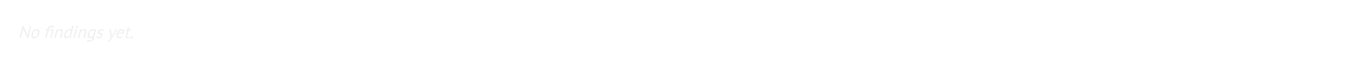

In [ ]:
# Summary: headline numbers, model table, what-ifs; resources to HF; close W&B
_out = [mo.md("_No findings yet._")]
if findings:
    _h = findings.get("headline", {})
    if log_fn is not None:
        log_fn({f"eda/{_k}": _v for _k, _v in _h.items() if isinstance(_v, (int, float))}, summary=True)
    _ms = pd.DataFrame(findings["models_summary"])
    _ms = _ms.pivot_table(index=["model", "label"], columns="split", values="f1_macro").round(2).reset_index()
    _out = [mo.md("## Headline numbers"), mo.ui.table(pd.DataFrame([{"what": _k, "value": _v} for _k, _v in _h.items()]), selection=None),
            mo.md("## Macro-F1 (%) per model and split"), mo.ui.table(_ms, selection=None),
            mo.md("## Post-hoc what-ifs on the primary model (each knob chosen on OOD val)"),
            mo.ui.table(pd.DataFrame(findings["whatif"]["stacked"]).round(2), selection=None),
            mo.md(f"Bundle for the report: `{wc.OUTPUTS_REPO}` → `eda/findings.json`, `eda/thumbs/`, `eda/fig_*.png`.")]
if RES_CSV.exists():
    hub.put({wc.resources_path(wc.EDA_RUN): RES_CSV}, "A1: resources")
wc.wandb_finish(wb_run)
mo.vstack(_out)